# Adsorption capacity prediction — Random Forest

This notebook trains and evaluates a **Random Forest** regression model for predicting experimental adsorption capacity, $q_e$ (mg g$^{-1}$).

This version implements the revised validation strategy requested for the 232-observation dataset: a single fixed **Training/Test** split, with no separate external-validation set. The dataset is sorted by the response variable before splitting; every third observation starting from the third is assigned to the Test set, while the final observation remains in Training.

## Analysis workflow
1. Load the audited combined modeling dataset (**232 observations**).
2. Sort the complete dataset by experimental $q_e$ in ascending order.
3. Apply the fixed split: every third observation, starting from the third, is assigned to the **Test** set; the final observation remains in **Training**.
4. Train the model using the same predefined configuration as in the previous analysis.
5. Evaluate predictive performance on the fixed **Training** and **Test** sets.
6. Perform **repeated 5-fold cross-validation ×10** only on the Training set as the internal validation procedure.
7. Report internal cross-validation metrics as **mean ± standard deviation across 50 validation folds**.
8. Generate residual and applicability-domain diagnostics for Training and Test.
9. Calculate SHAP values on the fixed Test set for model interpretation.
10. Save all model-specific outputs to one structured results folder on the Desktop.

## Terminology used throughout this notebook
- **Training** — the 155-record subset used for model fitting.
- **Test** — the fixed 77-record hold-out subset, not used for model fitting or internal cross-validation.
- **Internal cross-validation (CV)** — RepeatedKFold with 5 folds repeated 10 times on the Training set only, giving 50 validation-fold evaluations.
- **No separate external-validation set is used in this analysis.**

## Output structure
Running this notebook creates or updates:

`Desktop/Adsorption_qe_ML_results/Random_Forest/`

with three subfolders:
- `Figures/` — publication-quality PNG and PDF figures,
- `Tables/` — CSV tables and a consolidated Excel workbook,
- `Model/` — serialized model and configuration metadata.

The companion notebook writes to the same root folder, so only **one top-level results folder** is created on the Desktop.


## 1. Setup and output directories


In [1]:
MODEL_FOLDER_NAME = "Random_Forest"
MODEL_PREFIX = "RF"
MODEL_DISPLAY_NAME = "Random Forest"

from pathlib import Path
from datetime import datetime
from importlib.metadata import version
import json
import platform

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import shap

from IPython.display import display
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------------
# Reproducible file layout
# ------------------------------------------------------------------

def resolve_input_file(*filenames):
    """Locate the combined 232-observation dataset."""
    cwd = Path.cwd()
    for filename in filenames:
        candidates = [
            cwd / filename,
            cwd / "data" / filename,
            cwd.parent / "data" / filename,
        ]
        for candidate in candidates:
            if candidate.exists():
                return candidate.resolve()
    return cwd / filenames[0]

DATASET_PATH = resolve_input_file("dataset_232.csv", "dataset_new(2).csv")

def find_desktop():
    """Return a typical Desktop path on Windows, including OneDrive layouts."""
    home = Path.home()

    candidates = [
        home / "Desktop",
        home / "Pulpit",
        home / "OneDrive" / "Desktop",
        home / "OneDrive" / "Pulpit",
    ]

    for one_drive in home.glob("OneDrive*"):
        candidates.extend([
            one_drive / "Desktop",
            one_drive / "Pulpit",
        ])

    for candidate in candidates:
        if candidate.exists():
            return candidate

    fallback = home / "Desktop"
    fallback.mkdir(parents=True, exist_ok=True)
    return fallback

DESKTOP = find_desktop()
RESULTS_ROOT = DESKTOP / "Adsorption_qe_ML_results"
MODEL_RESULTS_DIR = RESULTS_ROOT / MODEL_FOLDER_NAME
FIGURES_DIR = MODEL_RESULTS_DIR / "Figures"
TABLES_DIR = MODEL_RESULTS_DIR / "Tables"
MODEL_DIR = MODEL_RESULTS_DIR / "Model"

for folder in [RESULTS_ROOT, MODEL_RESULTS_DIR, FIGURES_DIR, TABLES_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RUN_TIMESTAMP = datetime.now().isoformat(timespec="seconds")

print("Combined 232-observation dataset:", DATASET_PATH)
print("Results directory:", MODEL_RESULTS_DIR)

# ------------------------------------------------------------------
# Publication-quality figure style
# ------------------------------------------------------------------

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.grid": False,
})

FEATURE_LABELS = {
    "MLOGP": "MLOGP",
    "C0_mg_L": "Initial concentration (mg L$^{-1}$)",
    "pH": "pH",
    "Temperature_C": "Temperature (°C)",
    "Contact_time_min": "Contact time (min)",
    "Dose_g_L": "Adsorbent dose (g L$^{-1}$)",
    "BET_m2_g": "BET surface area (m$^2$ g$^{-1}$)",
    "qe_mg_g": "Adsorption capacity, $q_e$ (mg g$^{-1}$)",
}

def clean_axes(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out")
    ax.grid(False)
    return ax

def save_figure_dual(fig, stem):
    """Save a figure directly to the model-specific Figures folder."""
    png_path = FIGURES_DIR / f"{stem}.png"
    pdf_path = FIGURES_DIR / f"{stem}.pdf"
    fig.savefig(png_path, dpi=600, bbox_inches="tight", pad_inches=0.03)
    fig.savefig(pdf_path, bbox_inches="tight", pad_inches=0.03)
    return png_path, pdf_path

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

from sklearn.ensemble import RandomForestRegressor

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)
print("Matplotlib:", version("matplotlib"))


Combined 232-observation dataset: C:\Users\DELL\Desktop\dataset_232.csv
Results directory: C:\Users\DELL\Desktop\Adsorption_qe_ML_results\Random_Forest
Python: 3.13.9
NumPy: 2.3.5
pandas: 2.3.3
scikit-learn: 1.7.2
SHAP: 0.52.0
Matplotlib: 3.10.6


## 2. Load and validate the input data


In [2]:
FEATURES = [
    "MLOGP",
    "C0_mg_L",
    "pH",
    "Temperature_C",
    "Dose_g_L",
    "Contact_time_min",
    "BET_m2_g",
]
TARGET = "qe_mg_g"
EXPECTED_N = 232

required_columns = FEATURES + [TARGET]

def load_modeling_table(path, label):
    if not path.exists():
        raise FileNotFoundError(
            f"{label} file not found: {path}\n"
            "Place dataset_232.csv (or dataset_new(2).csv) in the working directory or data/ folder."
        )

    table = pd.read_csv(path, sep=";")
    table.columns = (
        table.columns
        .str.replace("\ufeff", "", regex=False)
        .str.strip()
    )

    missing_columns = [col for col in required_columns if col not in table.columns]
    if missing_columns:
        raise ValueError(f"{label} is missing required columns: {missing_columns}")

    for col in required_columns:
        table[col] = (
            table[col]
            .astype(str)
            .str.strip()
            .str.replace(",", ".", regex=False)
        )
        table[col] = pd.to_numeric(table[col], errors="coerce")

    table[required_columns] = table[required_columns].replace([np.inf, -np.inf], np.nan)

    invalid = table[table[required_columns].isna().any(axis=1)].copy()
    clean = table.dropna(subset=required_columns).reset_index(drop=True)

    print(f"{label}: {len(clean)} valid records")
    print(f"{label}: {len(invalid)} records removed because of missing/invalid model variables")
    print(f"{label}: {int(clean.duplicated(subset=required_columns).sum())} duplicate model rows (reported, not removed)")

    if len(invalid) > 0:
        display(invalid)

    return clean

model_df = load_modeling_table(DATASET_PATH, "Combined modeling dataset")

if len(model_df) != EXPECTED_N:
    raise ValueError(
        f"Expected {EXPECTED_N} valid observations for this analysis, found {len(model_df)}."
    )

# The split requested by the ML expert is defined on the response-sorted dataset.
# mergesort is stable, so the original order is preserved for tied qe values.
model_df = model_df.sort_values(TARGET, ascending=True, kind="mergesort").reset_index(drop=True)

print("Dataset sorted by qe:", bool(model_df[TARGET].is_monotonic_increasing))
print("Complete target range:", model_df[TARGET].min(), "to", model_df[TARGET].max(), "mg/g")
display(model_df.head())


Combined modeling dataset: 232 valid records
Combined modeling dataset: 0 records removed because of missing/invalid model variables
Combined modeling dataset: 0 duplicate model rows (reported, not removed)
Dataset sorted by qe: True
Complete target range: 0.56 to 723.2 mg/g


,MLOGP,C0_mg_L,pH,Temperature_C,Contact_time_min,Dose_g_L,BET_m2_g,qe_mg_g
0,-2.46,5.0,7.0,25.0,180.0,8.0,1200.00,0.560
1,1.28,1.0,7.0,25.0,50.0,1.0,219.00,0.950
2,-2.08,5.0,6.0,25.0,1440.0,4.0,64.32,1.125
3,-2.46,15.0,7.0,25.0,180.0,8.0,1200.00,1.779
4,-2.85,5.0,5.5,25.0,1440.0,2.0,4.30,1.840


## 3. Fixed Training / Test split


In [3]:
# Fixed split requested for the 232-observation analysis:
# after sorting by qe, every third record starting from the third is assigned to Test;
# the final (highest-qe) observation remains in Training.
test_idx = list(range(2, len(model_df) - 1, 3))

test_df = model_df.iloc[test_idx].copy()
train_df = model_df.drop(model_df.index[test_idx]).copy()

X_train = train_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

y_train = train_df[TARGET].copy()
y_test = test_df[TARGET].copy()

print("Training records:", len(train_df))
print("Test records:", len(test_df))
print("Total records:", len(train_df) + len(test_df))

print("\nTarget range — Training set:")
print("min =", y_train.min(), "max =", y_train.max())

print("\nTarget range — Test set:")
print("min =", y_test.min(), "max =", y_test.max())

print("\nHighest-qe observation retained in Training:", model_df.index[-1] not in test_idx)
print("Highest qe in complete dataset:", model_df[TARGET].iloc[-1])
print("Highest qe in Training:", y_train.max())


Training records: 155
Test records: 77
Total records: 232

Target range — Training set:
min = 0.56 max = 723.2

Target range — Test set:
min = 1.125 max = 675.825

Highest-qe observation retained in Training: True
Highest qe in complete dataset: 723.2
Highest qe in Training: 723.2


## 4. Train the Random Forest model


In [4]:
MODEL = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    min_samples_leaf=2,
    n_jobs=-1,
)

MODEL.fit(X_train, y_train)
CV_N_JOBS = None

print("The Random Forest model has been trained.")
print("Predictors used by the model:")
print(list(MODEL.feature_names_in_))

feature_importance_table = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": MODEL.feature_importances_,
}).sort_values("Importance", ascending=False)

display(feature_importance_table)


The Random Forest model has been trained.
Predictors used by the model:
['MLOGP', 'C0_mg_L', 'pH', 'Temperature_C', 'Dose_g_L', 'Contact_time_min', 'BET_m2_g']


,Feature,Importance
4,Dose_g_L,0.445329
1,C0_mg_L,0.294985
3,Temperature_C,0.122666
6,BET_m2_g,0.078024
5,Contact_time_min,0.040081
0,MLOGP,0.011349
2,pH,0.007565


## 5. Predictive performance on Training and Test

The **Test** set is the fixed 77-record hold-out subset selected before model fitting from the response-sorted 232-observation dataset. It is not used for model fitting or repeated internal cross-validation.


In [5]:
# Predictions for the two fixed datasets
y_train_pred = MODEL.predict(X_train)
y_test_pred = MODEL.predict(X_test)

metrics_table = pd.DataFrame([
    {
        "Evaluation": "Training",
        "N": len(y_train),
        "R2": r2_score(y_train, y_train_pred),
        "MAE": mean_absolute_error(y_train, y_train_pred),
        "RMSE": rmse(y_train, y_train_pred),
    },
    {
        "Evaluation": "Test",
        "N": len(y_test),
        "R2": r2_score(y_test, y_test_pred),
        "MAE": mean_absolute_error(y_test, y_test_pred),
        "RMSE": rmse(y_test, y_test_pred),
    },
])

test_metrics_table = metrics_table.loc[
    metrics_table["Evaluation"] == "Test"
].copy()

print("FIXED-DATASET PERFORMANCE")
display(
    metrics_table.style.format({
        "R2": "{:.9f}",
        "MAE": "{:.5f}",
        "RMSE": "{:.5f}",
    })
)


FIXED-DATASET PERFORMANCE


,Evaluation,N,R2,MAE,RMSE
0,Training,155,0.940085457,13.57771,28.34175
1,Test,77,0.734387909,32.18825,60.23745


## 6. Internal validation — repeated 5-fold cross-validation ×10


In [6]:
# Repeated internal cross-validation is performed ONLY on the Training set.
# The fixed Test set remains untouched.
CV_N_SPLITS = 5
CV_N_REPEATS = 10
CV_RANDOM_STATE = 42

cv = RepeatedKFold(
    n_splits=CV_N_SPLITS,
    n_repeats=CV_N_REPEATS,
    random_state=CV_RANDOM_STATE,
)

cv_results = cross_validate(
    MODEL,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "R2": "r2",
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
    },
    return_train_score=False,
    n_jobs=CV_N_JOBS,
)

# scikit-learn uses the standard keys "test_*" for the held-out fold
# within cross-validation. These are internal CV validation-fold scores,
# not the fixed Test set defined above.
cv_r2 = cv_results["test_R2"]
cv_mae = -cv_results["test_MAE"]
cv_rmse = -cv_results["test_RMSE"]

cv_folds_table = pd.DataFrame({
    "Evaluation": np.arange(1, len(cv_r2) + 1),
    "Repeat": np.repeat(np.arange(1, CV_N_REPEATS + 1), CV_N_SPLITS),
    "Fold": np.tile(np.arange(1, CV_N_SPLITS + 1), CV_N_REPEATS),
    "R2": cv_r2,
    "MAE": cv_mae,
    "RMSE": cv_rmse,
})

cv_summary_table = pd.DataFrame([{
    "Evaluation": "Repeated 5-fold CV ×10",
    "N_evaluations": len(cv_r2),
    "R2_mean": cv_r2.mean(),
    "R2_SD": cv_r2.std(ddof=1),
    "MAE_mean": cv_mae.mean(),
    "MAE_SD": cv_mae.std(ddof=1),
    "RMSE_mean": cv_rmse.mean(),
    "RMSE_SD": cv_rmse.std(ddof=1),
    "Performed_on": "Training set only",
}])

performance_summary_table = pd.DataFrame([
    {
        "Evaluation": "Training",
        "N_or_evaluations": len(y_train),
        "R2": r2_score(y_train, y_train_pred),
        "R2_SD": np.nan,
        "MAE": mean_absolute_error(y_train, y_train_pred),
        "MAE_SD": np.nan,
        "RMSE": rmse(y_train, y_train_pred),
        "RMSE_SD": np.nan,
        "Notes": "Model fitted on this dataset.",
    },
    {
        "Evaluation": "Test",
        "N_or_evaluations": len(y_test),
        "R2": r2_score(y_test, y_test_pred),
        "R2_SD": np.nan,
        "MAE": mean_absolute_error(y_test, y_test_pred),
        "MAE_SD": np.nan,
        "RMSE": rmse(y_test, y_test_pred),
        "RMSE_SD": np.nan,
        "Notes": "Fixed hold-out Test set; selected before fitting from the qe-sorted dataset and not used for fitting or internal CV.",
    },
    {
        "Evaluation": "Repeated 5-fold CV ×10",
        "N_or_evaluations": len(cv_r2),
        "R2": cv_r2.mean(),
        "R2_SD": cv_r2.std(ddof=1),
        "MAE": cv_mae.mean(),
        "MAE_SD": cv_mae.std(ddof=1),
        "RMSE": cv_rmse.mean(),
        "RMSE_SD": cv_rmse.std(ddof=1),
        "Notes": "Mean ± sample SD across 50 internal validation folds; performed on Training set only.",
    },
])

performance_display = pd.DataFrame([
    {
        "Evaluation": "Training",
        "N / evaluations": str(len(y_train)),
        "R2": f"{r2_score(y_train, y_train_pred):.6f}",
        "MAE": f"{mean_absolute_error(y_train, y_train_pred):.5f}",
        "RMSE": f"{rmse(y_train, y_train_pred):.5f}",
    },
    {
        "Evaluation": "Test",
        "N / evaluations": str(len(y_test)),
        "R2": f"{r2_score(y_test, y_test_pred):.6f}",
        "MAE": f"{mean_absolute_error(y_test, y_test_pred):.5f}",
        "RMSE": f"{rmse(y_test, y_test_pred):.5f}",
    },
    {
        "Evaluation": "Repeated 5-fold CV ×10",
        "N / evaluations": f"{len(cv_r2)} folds",
        "R2": f"{cv_r2.mean():.6f} ± {cv_r2.std(ddof=1):.6f}",
        "MAE": f"{cv_mae.mean():.5f} ± {cv_mae.std(ddof=1):.5f}",
        "RMSE": f"{cv_rmse.mean():.5f} ± {cv_rmse.std(ddof=1):.5f}",
    },
])

print(f"Internal validation: repeated {CV_N_SPLITS}-fold cross-validation ×{CV_N_REPEATS}")
print("Number of validation-fold evaluations:", len(cv_r2))
print("Cross-validation metrics are reported as mean ± sample SD across the 50 validation folds.")
display(performance_display)


Internal validation: repeated 5-fold cross-validation ×10
Number of validation-fold evaluations: 50
Cross-validation metrics are reported as mean ± sample SD across the 50 validation folds.


,Evaluation,N / evaluations,R2,MAE,RMSE
0,Training,155,0.940085,13.57771,28.34175
1,Test,77,0.734388,32.18825,60.23745
2,Repeated 5-fold CV ×10,50 folds,0.746679 ± 0.105390,30.33108 ± 9.45337,54.34203 ± 20.37339


## 7. Observed versus predicted values


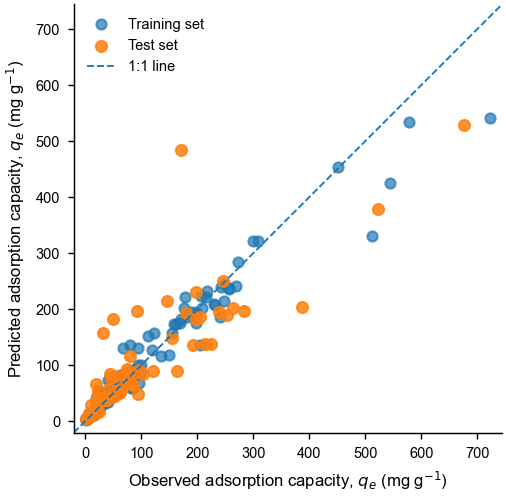

In [7]:
fig, ax = plt.subplots(figsize=(3.55, 3.55))

ax.scatter(y_train, y_train_pred, s=24, alpha=0.70, label="Training set")
ax.scatter(y_test, y_test_pred, s=28, alpha=0.85, label="Test set")

all_observed = np.concatenate([np.asarray(y_train), np.asarray(y_test)])
all_predicted = np.concatenate([np.asarray(y_train_pred), np.asarray(y_test_pred)])

plot_min = min(all_observed.min(), all_predicted.min())
plot_max = max(all_observed.max(), all_predicted.max())
margin = 0.03 * (plot_max - plot_min if plot_max > plot_min else 1.0)
plot_min -= margin
plot_max += margin

ax.plot([plot_min, plot_max], [plot_min, plot_max], linestyle="--", linewidth=0.9, label="1:1 line")
ax.set_xlim(plot_min, plot_max)
ax.set_ylim(plot_min, plot_max)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Observed adsorption capacity, $q_e$ (mg g$^{-1}$)")
ax.set_ylabel("Predicted adsorption capacity, $q_e$ (mg g$^{-1}$)")
ax.legend(frameon=False, loc="best")
clean_axes(ax)
fig.tight_layout()

save_figure_dual(fig, f"{MODEL_PREFIX}_observed_vs_predicted")
plt.show()
plt.close(fig)


## 8. Residual analysis


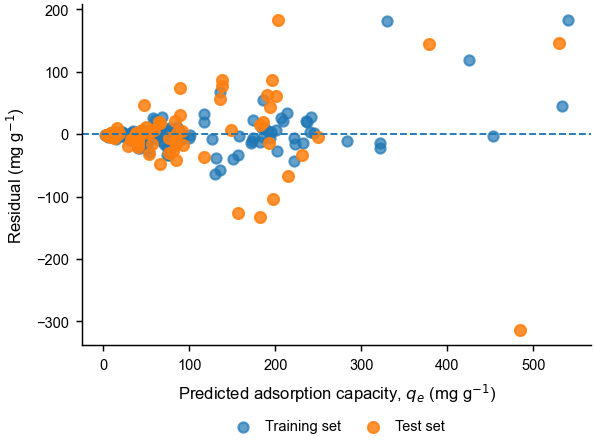

In [8]:
# Residual = observed - predicted
residuals_train = np.asarray(y_train) - np.asarray(y_train_pred)
residuals_test = np.asarray(y_test) - np.asarray(y_test_pred)

fig, ax = plt.subplots(figsize=(4.15, 3.15))

ax.scatter(y_train_pred, residuals_train, s=24, alpha=0.70, label="Training set")
ax.scatter(y_test_pred, residuals_test, s=28, alpha=0.85, label="Test set")

ax.axhline(0, linestyle="--", linewidth=0.9)
ax.set_xlabel("Predicted adsorption capacity, $q_e$ (mg g$^{-1}$)")
ax.set_ylabel("Residual (mg g$^{-1}$)")
ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    handletextpad=0.5,
    columnspacing=1.2,
)
clean_axes(ax)
fig.tight_layout()
fig.subplots_adjust(bottom=0.24)

save_figure_dual(fig, f"{MODEL_PREFIX}_residuals_vs_predicted")
plt.show()
plt.close(fig)


## 9. Applicability-domain diagnostic


Number of training records: 155
Number of predictors: 7
Leverage threshold h* = 0.1548
Training-set RMSE = 28.3417


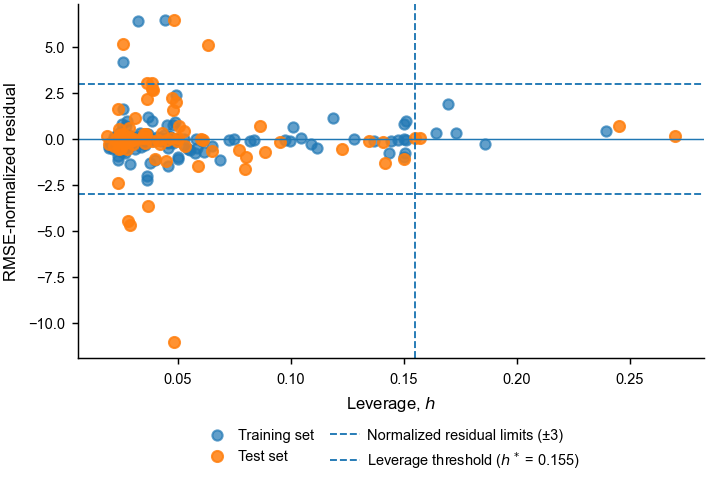

Test records inside the applicability domain: 65 / 77


,MLOGP,C0_mg_L,pH,Temperature_C,Dose_g_L,Contact_time_min,BET_m2_g,qe_mg_g,Predicted_qe_mg_g,Leverage,Normalized_residual
77,-2.46,100.0,7.0,25.0,0.50,1440.0,43.7194,30.600,156.752423,0.027880,-4.451116
113,-2.46,100.0,4.0,30.0,0.20,720.0,34.2200,49.580,182.511228,0.028932,-4.690297
158,-2.46,500.0,7.0,30.0,5.00,30.0,77.4200,87.380,86.017747,0.156968,0.048065
161,-2.46,100.0,7.0,25.0,0.20,90.0,96.9000,92.500,196.827473,0.036578,-3.681053
167,-2.46,600.0,7.0,20.0,5.00,30.0,77.4200,95.900,91.129039,0.270109,0.168337
170,-2.46,600.0,7.0,40.0,5.00,30.0,77.4200,103.380,83.082236,0.245495,0.716179
185,-2.46,100.0,6.0,20.0,0.10,4320.0,959.9000,171.510,484.584745,0.048286,-11.046416
206,1.28,20.0,6.5,19.0,0.05,2880.0,43.8000,224.000,137.520215,0.038481,3.051321
221,1.28,20.0,6.5,19.0,0.05,2880.0,110.2000,283.000,196.488642,0.036078,3.052435
224,-2.46,200.0,7.0,25.0,0.50,2880.0,807.3000,386.400,202.914382,0.048036,6.474040


In [9]:
# The diagnostic uses leverage in standardized predictor space and
# RMSE-normalized residuals. The leverage threshold is h* = 3(p + 1) / n.

scaler_ad = StandardScaler()
X_train_scaled = scaler_ad.fit_transform(X_train)
X_test_scaled = scaler_ad.transform(X_test)

X_train_design = np.column_stack([np.ones(len(X_train_scaled)), X_train_scaled])
X_test_design = np.column_stack([np.ones(len(X_test_scaled)), X_test_scaled])

xtx_inverse = np.linalg.pinv(X_train_design.T @ X_train_design)

h_train = np.diag(X_train_design @ xtx_inverse @ X_train_design.T)
h_test = np.einsum("ij,jk,ik->i", X_test_design, xtx_inverse, X_test_design)

n_train = len(X_train)
p = len(FEATURES)
h_star = 3 * (p + 1) / n_train

rmse_train = rmse(y_train, y_train_pred)
if rmse_train == 0:
    raise ValueError("Training-set RMSE is 0; normalized residuals cannot be calculated.")

std_res_train = residuals_train / rmse_train
std_res_test = residuals_test / rmse_train

print("Number of training records:", n_train)
print("Number of predictors:", p)
print("Leverage threshold h* =", round(h_star, 4))
print("Training-set RMSE =", round(rmse_train, 4))

fig, ax = plt.subplots(figsize=(4.9, 3.45))
ax.scatter(h_train, std_res_train, s=24, alpha=0.70, label="Training set")
ax.scatter(h_test, std_res_test, s=28, alpha=0.85, label="Test set")
ax.axhline(0, linewidth=0.7)
ax.axhline(3, linestyle="--", linewidth=0.9, label="Normalized residual limits (±3)")
ax.axhline(-3, linestyle="--", linewidth=0.9)
ax.axvline(h_star, linestyle="--", linewidth=0.9, label=f"Leverage threshold ($h^*$ = {h_star:.3f})")
ax.set_xlabel("Leverage, $h$")
ax.set_ylabel("RMSE-normalized residual")
ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    handletextpad=0.5,
    columnspacing=1.1,
    borderaxespad=0,
)
clean_axes(ax)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)

save_figure_dual(fig, f"{MODEL_PREFIX}_leverage_residual_applicability_domain")
plt.show()
plt.close(fig)

test_ad = test_df.copy()
test_ad["Predicted_qe_mg_g"] = y_test_pred
test_ad["Residual_mg_g"] = residuals_test
test_ad["Normalized_residual"] = std_res_test
test_ad["Leverage"] = h_test
test_ad["High_leverage"] = test_ad["Leverage"] > h_star
test_ad["Large_residual"] = np.abs(test_ad["Normalized_residual"]) > 3
test_ad["Inside_AD"] = ~(test_ad["High_leverage"] | test_ad["Large_residual"])

print(
    "Test records inside the applicability domain:",
    int(test_ad["Inside_AD"].sum()),
    "/",
    len(test_ad),
)

columns_to_show = FEATURES + [TARGET, "Predicted_qe_mg_g", "Leverage", "Normalized_residual"]
display(test_ad.loc[~test_ad["Inside_AD"], columns_to_show])


## 10. SHAP interpretation on the Test set


In [10]:
# SHAP values are calculated on the fixed Test set (77-record hold-out subset).
print("SHAP version:", shap.__version__)

explainer = shap.TreeExplainer(
    MODEL,
    feature_perturbation="tree_path_dependent",
    model_output="raw",
)

shap_values_test = np.asarray(
    explainer.shap_values(X_test, check_additivity=True)
)

base_value = float(np.asarray(explainer.expected_value).reshape(-1)[0])
shap_reconstructed = base_value + shap_values_test.sum(axis=1)
SHAP_MAX_ADDITIVITY_DIFFERENCE = float(
    np.max(np.abs(np.asarray(y_test_pred) - shap_reconstructed))
)

print("Maximum SHAP additivity difference:", SHAP_MAX_ADDITIVITY_DIFFERENCE)


SHAP version: 0.52.0
Maximum SHAP additivity difference: 1.7337242752546445e-12


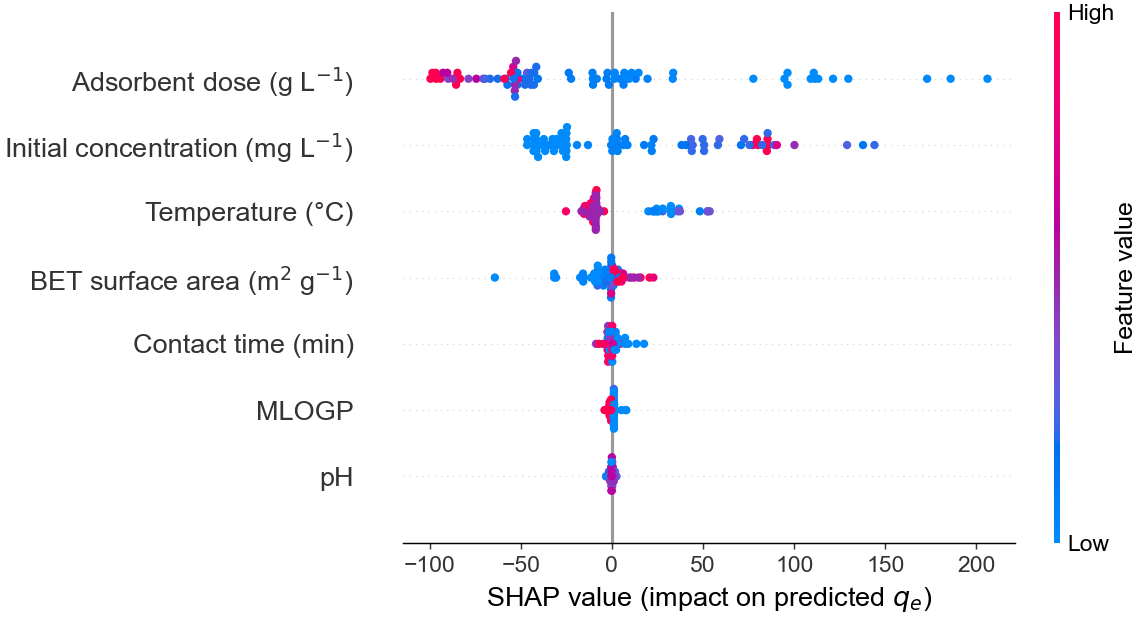

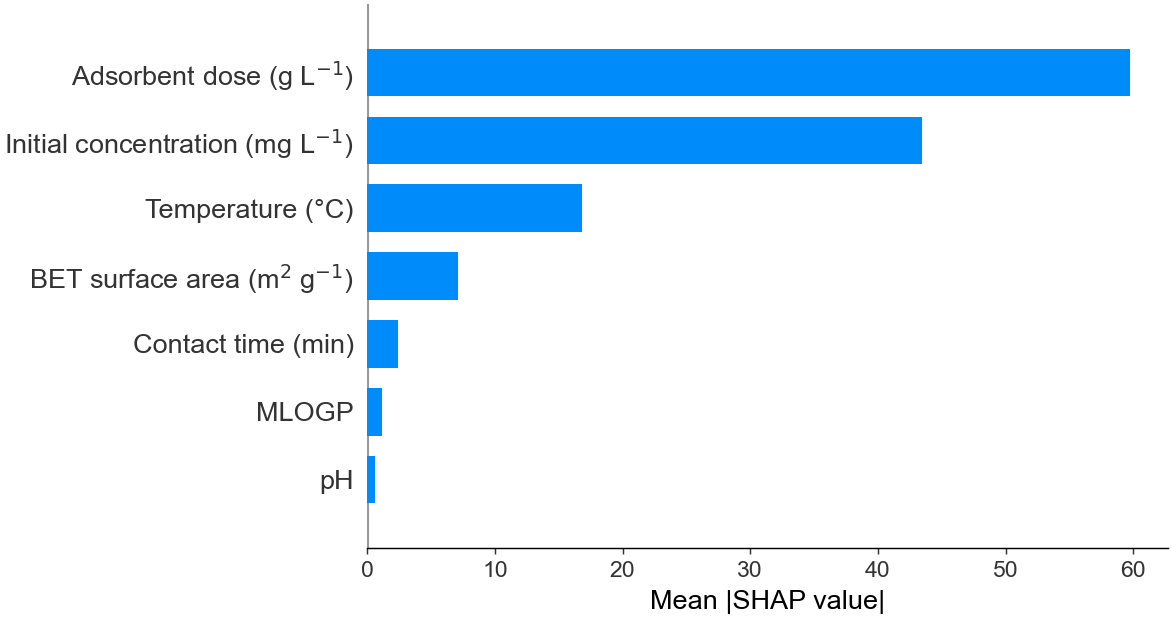

,Feature,Mean_absolute_SHAP
4,Dose_g_L,59.771881
1,C0_mg_L,43.471056
3,Temperature_C,16.860739
6,BET_m2_g,7.098589
5,Contact_time_min,2.431352
0,MLOGP,1.130247
2,pH,0.628766


Predictors selected for SHAP dependence plots: ['Dose_g_L', 'C0_mg_L', 'Temperature_C']


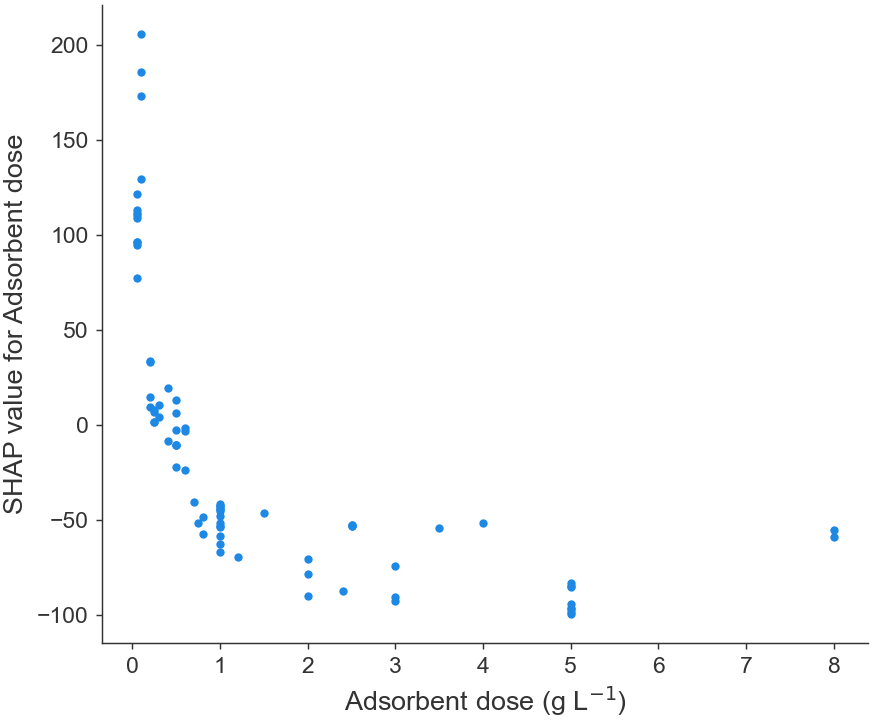

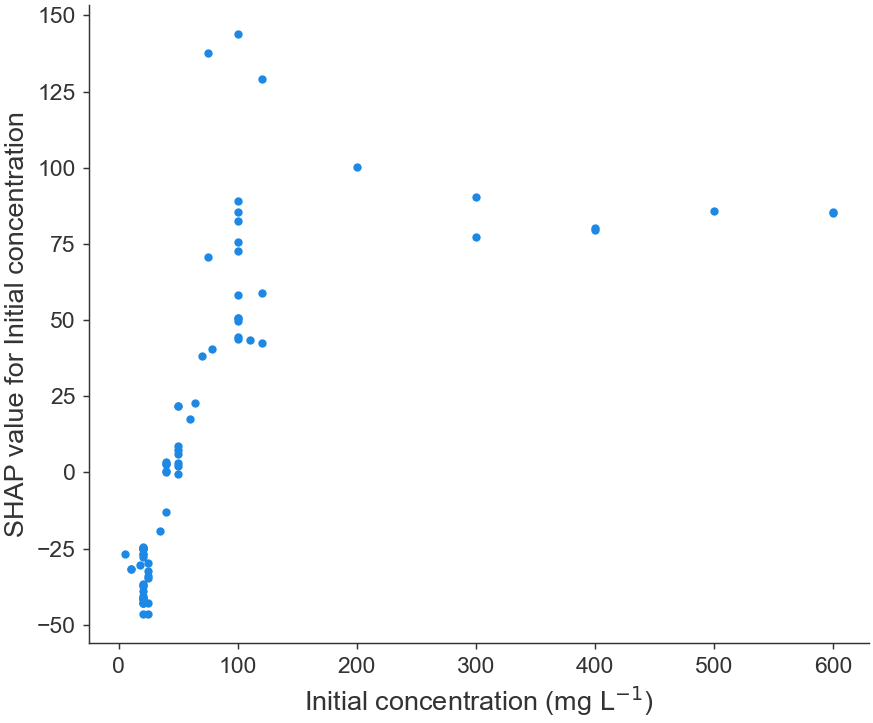

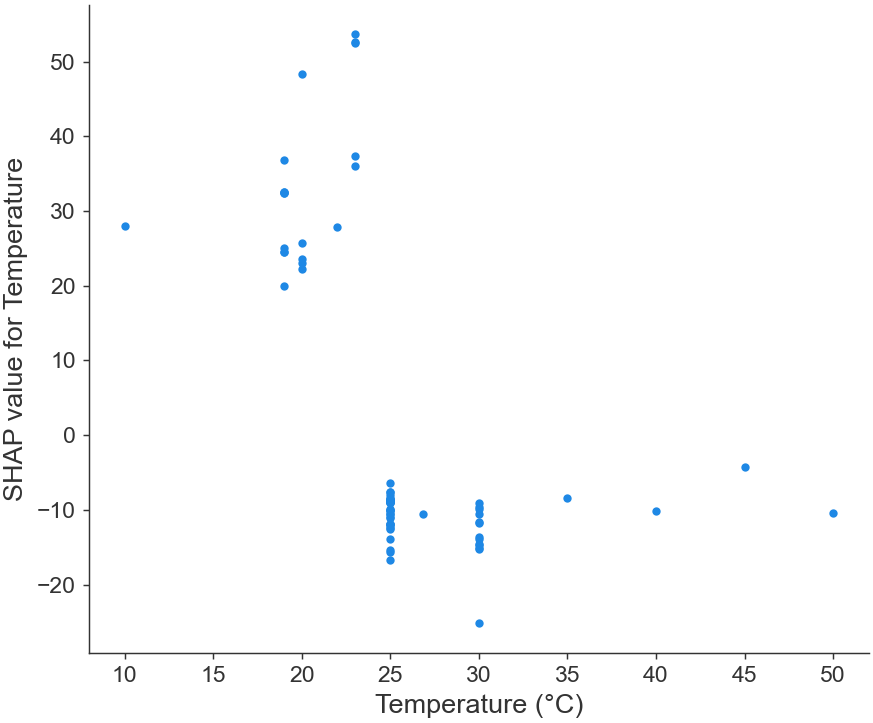

In [11]:
X_test_display = X_test.copy()
X_test_display.columns = [FEATURE_LABELS.get(col, col) for col in X_test_display.columns]

shap.summary_plot(shap_values_test, X_test_display, show=False)
fig = plt.gcf()
ax = plt.gca()
ax.set_xlabel("SHAP value (impact on predicted $q_e$)")
clean_axes(ax)
fig.tight_layout()
save_figure_dual(fig, f"{MODEL_PREFIX}_SHAP_summary")
plt.show()
plt.close(fig)

shap.summary_plot(shap_values_test, X_test_display, plot_type="bar", show=False)
fig = plt.gcf()
ax = plt.gca()
ax.set_xlabel("Mean |SHAP value|")
clean_axes(ax)
fig.tight_layout()
save_figure_dual(fig, f"{MODEL_PREFIX}_SHAP_importance")
plt.show()
plt.close(fig)

mean_abs_shap = np.abs(shap_values_test).mean(axis=0)
shap_importance_table = pd.DataFrame({
    "Feature": FEATURES,
    "Mean_absolute_SHAP": mean_abs_shap,
}).sort_values("Mean_absolute_SHAP", ascending=False)

display(shap_importance_table)

top_features = shap_importance_table["Feature"].head(min(3, len(FEATURES))).tolist()
print("Predictors selected for SHAP dependence plots:", top_features)

for rank, feature_name in enumerate(top_features, start=1):
    shap.dependence_plot(
        feature_name,
        shap_values_test,
        X_test,
        interaction_index=None,
        show=False,
    )
    fig = plt.gcf()
    ax = plt.gca()
    ax.set_xlabel(FEATURE_LABELS.get(feature_name, feature_name))
    short_label = FEATURE_LABELS.get(feature_name, feature_name).split(" (")[0]
    ax.set_ylabel(f"SHAP value for {short_label}")
    clean_axes(ax)
    fig.tight_layout()

    safe_name = feature_name.replace(" ", "_").replace("/", "_")
    save_figure_dual(fig, f"{MODEL_PREFIX}_SHAP_dependence_{rank}_{safe_name}")
    plt.show()
    plt.close(fig)


## 11. Export all results


In [12]:
# ------------------------------------------------------------------
# Tables
# ------------------------------------------------------------------

train_results = train_df.copy()
train_results["Observed_qe_mg_g"] = np.asarray(y_train)
train_results["Predicted_qe_mg_g"] = np.asarray(y_train_pred)
train_results["Residual_mg_g"] = np.asarray(residuals_train)

test_results = test_df.copy()
test_results["Observed_qe_mg_g"] = np.asarray(y_test)
test_results["Predicted_qe_mg_g"] = np.asarray(y_test_pred)
test_results["Residual_mg_g"] = np.asarray(residuals_test)

shap_values_table = pd.DataFrame(shap_values_test, columns=FEATURES)
shap_values_table.insert(0, "Test_row_index", test_df.index.to_numpy())

table_exports = {
    f"{MODEL_PREFIX}_performance_summary.csv": performance_summary_table,
    f"{MODEL_PREFIX}_fixed_dataset_metrics.csv": metrics_table,
    f"{MODEL_PREFIX}_test_metrics.csv": test_metrics_table,
    f"{MODEL_PREFIX}_cross_validation_folds.csv": cv_folds_table,
    f"{MODEL_PREFIX}_cross_validation_summary.csv": cv_summary_table,
    f"{MODEL_PREFIX}_feature_importance.csv": feature_importance_table,
    f"{MODEL_PREFIX}_SHAP_importance.csv": shap_importance_table,
    f"{MODEL_PREFIX}_SHAP_values_test.csv": shap_values_table,
    f"{MODEL_PREFIX}_predictions_training.csv": train_results,
    f"{MODEL_PREFIX}_predictions_test.csv": test_results,
    f"{MODEL_PREFIX}_test_applicability_domain.csv": test_ad,
}

for filename, table in table_exports.items():
    table.to_csv(TABLES_DIR / filename, index=False)

excel_path = MODEL_RESULTS_DIR / f"{MODEL_PREFIX}_qe_complete_results.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    performance_summary_table.to_excel(writer, sheet_name="Performance_summary", index=False)
    metrics_table.to_excel(writer, sheet_name="Fixed_dataset_metrics", index=False)
    test_metrics_table.to_excel(writer, sheet_name="Test_metrics", index=False)
    cv_folds_table.to_excel(writer, sheet_name="CV_folds", index=False)
    cv_summary_table.to_excel(writer, sheet_name="CV_summary", index=False)
    feature_importance_table.to_excel(writer, sheet_name="Feature_importance", index=False)
    shap_importance_table.to_excel(writer, sheet_name="SHAP_importance", index=False)
    shap_values_table.to_excel(writer, sheet_name="SHAP_values_test", index=False)
    train_results.to_excel(writer, sheet_name="Predictions_training", index=False)
    test_results.to_excel(writer, sheet_name="Predictions_test", index=False)
    test_ad.to_excel(writer, sheet_name="Test_AD", index=False)

# ------------------------------------------------------------------
# Model and configuration
# ------------------------------------------------------------------

joblib_model_path = MODEL_DIR / "RandomForest_qe_model.joblib"
joblib.dump(MODEL, joblib_model_path)

configuration = {
    "run_timestamp": RUN_TIMESTAMP,
    "dataset_file": DATASET_PATH.name,
    "dataset_n": int(len(model_df)),
    "features": FEATURES,
    "target": TARGET,
    "data_order_before_split": "sorted by qe_mg_g ascending using stable mergesort",
    "split_rule": "test_idx = list(range(2, len(model_df) - 1, 3))",
    "split_terminology": {
        "training": f"{len(train_df)}-record subset used for model fitting",
        "test": f"fixed {len(test_df)}-record hold-out subset, not used for fitting or internal CV",
        "external_validation": "not used in this revised two-set analysis",
    },
    "model_parameters": MODEL.get_params(deep=False),
    "n_training": int(len(train_df)),
    "n_test": int(len(test_df)),
    "fixed_dataset_performance": {
        row["Evaluation"]: {
            "N": int(row["N"]),
            "R2": float(row["R2"]),
            "MAE": float(row["MAE"]),
            "RMSE": float(row["RMSE"]),
        }
        for row in metrics_table.to_dict(orient="records")
    },
    "internal_cross_validation": {
        "method": "RepeatedKFold",
        "n_splits": CV_N_SPLITS,
        "n_repeats": CV_N_REPEATS,
        "n_validation_fold_evaluations": int(len(cv_r2)),
        "random_state": CV_RANDOM_STATE,
        "performed_on": "Training set only",
        "reporting": "mean ± sample standard deviation across 50 validation folds",
        "R2_mean": float(cv_r2.mean()),
        "R2_SD": float(cv_r2.std(ddof=1)),
        "MAE_mean": float(cv_mae.mean()),
        "MAE_SD": float(cv_mae.std(ddof=1)),
        "RMSE_mean": float(cv_rmse.mean()),
        "RMSE_SD": float(cv_rmse.std(ddof=1)),
    },
    "applicability_domain": {
        "method": "standardized predictor-space leverage + RMSE-normalized residual",
        "leverage_threshold_h_star": float(h_star),
        "residual_limit": 3.0,
        "evaluated_on": "Training and fixed Test sets",
    },
    "software_versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "shap": shap.__version__,
        "matplotlib": version("matplotlib"),
    },
    "SHAP": {
        "explainer": "shap.TreeExplainer",
        "feature_perturbation": "tree_path_dependent",
        "model_output": "raw",
        "check_additivity": True,
        "evaluation_dataset": "Test",
        "max_additivity_difference": float(SHAP_MAX_ADDITIVITY_DIFFERENCE),
    },
}

configuration_path = MODEL_DIR / "RandomForest_configuration.json"
with open(configuration_path, "w", encoding="utf-8") as file:
    json.dump(configuration, file, ensure_ascii=False, indent=2, default=str)

print("=" * 78)
print(f"{MODEL_DISPLAY_NAME.upper()} ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 78)
print("\nResults directory:")
print(MODEL_RESULTS_DIR)
print("\nSaved output groups:")
print(f"- Figures: {FIGURES_DIR}")
print(f"- Tables:  {TABLES_DIR}")
print(f"- Model:   {MODEL_DIR}")
print(f"- Consolidated workbook: {excel_path.name}")

print("\nFINAL PERFORMANCE SUMMARY")
display(performance_display)


RANDOM FOREST ANALYSIS COMPLETED SUCCESSFULLY

Results directory:
C:\Users\DELL\Desktop\Adsorption_qe_ML_results\Random_Forest

Saved output groups:
- Figures: C:\Users\DELL\Desktop\Adsorption_qe_ML_results\Random_Forest\Figures
- Tables:  C:\Users\DELL\Desktop\Adsorption_qe_ML_results\Random_Forest\Tables
- Model:   C:\Users\DELL\Desktop\Adsorption_qe_ML_results\Random_Forest\Model
- Consolidated workbook: RF_qe_complete_results.xlsx

FINAL PERFORMANCE SUMMARY


,Evaluation,N / evaluations,R2,MAE,RMSE
0,Training,155,0.940085,13.57771,28.34175
1,Test,77,0.734388,32.18825,60.23745
2,Repeated 5-fold CV ×10,50 folds,0.746679 ± 0.105390,30.33108 ± 9.45337,54.34203 ± 20.37339
